# Three acoustic branches in a cubic crystal

Rotate the propagation direction without changing density or stiffness. Predict which two modes coincide along a cube edge and compare the computed [110] speeds with the three analytic eigenvalues. Then impose the isotropic condition.

Run this cell with OneSimulation, NumPy and Matplotlib installed. Adjust the parameters and rerun to compare with the reference output below.


Wave speeds in km/s, sorted by magnitude
[100] 5.860 5.860 8.441
[110] 4.679 5.860 9.148


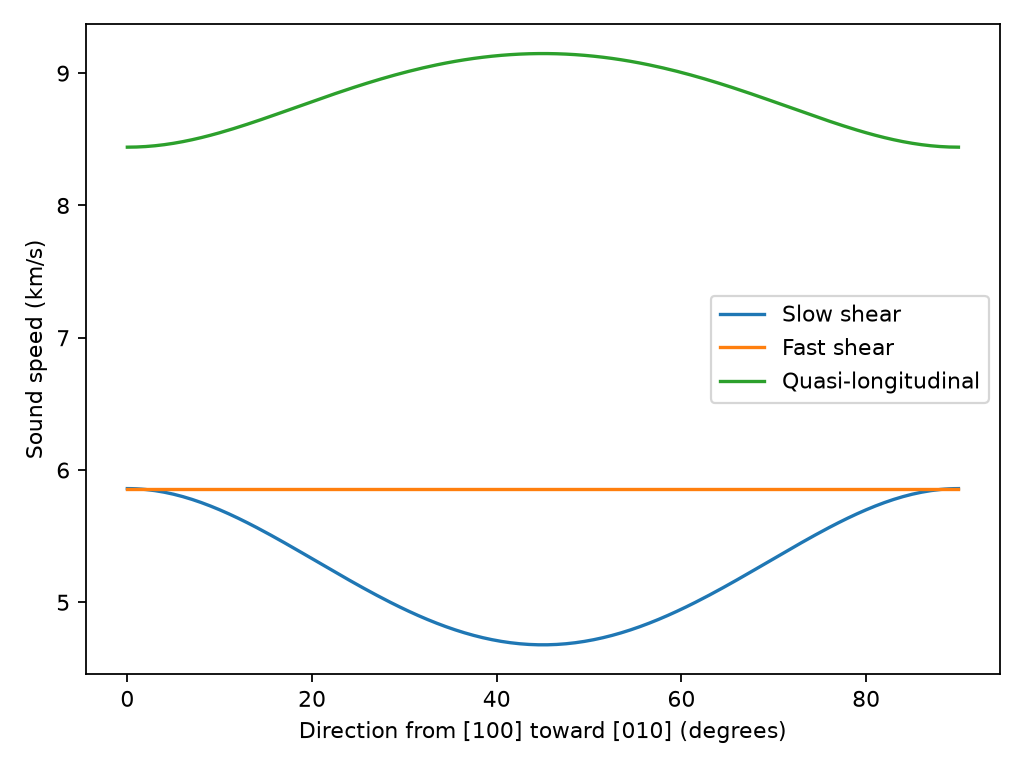

In [1]:
"""Sound velocities when a wave rotates through the (001) plane of a cubic solid."""
import numpy as np
import matplotlib.pyplot as plt
from onesim.numerics.linear.matrices.dense_linear_algebra import symmetric_eigenvalues

c11, c12, c44 = np.array([166, 64, 80]) * 1e9  # Pa
density = 2330.0  # kg/m^3

def speeds(angle):
    n = np.array([np.cos(angle), np.sin(angle), 0])
    gamma = (c12+c44) * np.outer(n, n)
    gamma += np.diag(c44 + (c11-c12-2*c44)*n**2)
    return np.sqrt(symmetric_eigenvalues(gamma)/density)

angle = np.linspace(0, np.pi/2, 181)
velocity = np.array([speeds(a) for a in angle]) / 1000
print("Wave speeds in km/s, sorted by magnitude")
for label, a in [("[100]", 0), ("[110]", np.pi/4)]:
    print(label, " ".join(f"{v/1000:.3f}" for v in speeds(a)))
for branch, label in enumerate(["Slow shear", "Fast shear", "Quasi-longitudinal"]):
    plt.plot(np.degrees(angle), velocity[:,branch], label=label)
plt.xlabel("Direction from [100] toward [010] (degrees)")
plt.ylabel("Sound speed (km/s)")
plt.legend()
plt.tight_layout()
plt.savefig("physics-cubic-sound.png", dpi=160)

plt.show()
